# Guía de Trabajo: ACP y Clustering
---

## Objetivo

Aplicar ACP a cinco data sets de acceso públicos para explorar la estructura interna de los datos, reducir la dimensionalidad y visualizar patrones

| Dataset   | Descripción                                           | Enlace                                                                                 |
| --        | --                                                    | --                                                                                     |
| Wine      | Composición química de vinos italianos                | [Wine](https://archive.ics.uci.edu/dataset/109/wine)                                   |
| Iris      | Medidas de sépalos y pétalos de tres especies de Iris | [Iris](https://archive.ics.uci.edu/dataset/53/iris)                                    |
| USArrests | Estadísticas de arrestos en EE.UU.                    | [Housing](https://github.com/ageron/handson-ml2/tree/master/datasets/housing)          |
| Human Activity Recognition | Datos de sensores de smartphones     | [Human](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones) |
| Olive Oil | Composición química de aceites de oliva               | [Olive Oil](https://service.tib.eu/ldmservice/dataset/olive-oil)                       |

In [2]:
library(FactoMineR)
library(factoextra)
library(ggplot2)
library(tidyverse)
library(cluster)
library(readr)

## Wine

In [3]:
# Cargar el dataset
df <- read_csv('/Users/ppando/Materias/cs-datos/especializacion/data/wine.csv', show_col_types = FALSE)
colnames(df) <- c('class', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash', 'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols', 
 'Proanthocyanins', 'Color intensity', 'Hue', 'OD280/OD315 of diluted wines',  'Proline')
head(df)

class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450
1,14.39,1.87,2.45,14.6,96,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290


In [4]:
# Guardar la clase como factor (para colorear y elipses)
clase <- factor(df$class, labels = c('Clase1', 'Clase2', 'Clase3'))

In [5]:
# Seleccionar variables numéricas (sin la clase)
# X <- df %>% select(where(is.numeric))
X <- df %>% select(-class)

In [6]:
# Aplicar ACP
pca <- PCA(X, graph = FALSE)

Ignoring unknown labels:
• linetype : "Clase"


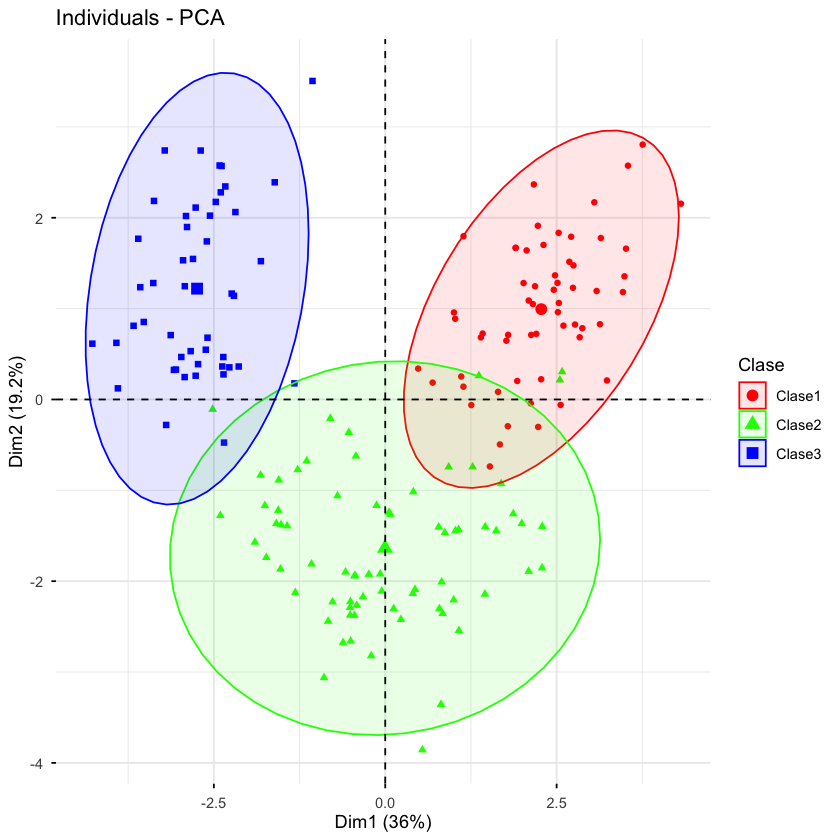

In [7]:
# Visualizar individuos en PC1 y PC2
fviz_pca_ind(pca,
             geom = "point",
             habillage = clase,
             palette = c("red", "green", "blue"),
             addEllipses = TRUE,
             legend.title = "Clase")

In [8]:
# Autovalores
pca$eig[,1]

comp 1    comp 2    comp 3    comp 4    comp 5    comp 6    comp 7    comp 8 
4.6777992 2.5013663 1.4533298 0.9244441 0.8617367 0.6448477 0.5519818 0.3507388 
   comp 9   comp 10   comp 11   comp 12   comp 13 
0.2891800 0.2468087 0.2254402 0.1683768 0.1039497

In [9]:
# % de varianza explicada
pca$eig[,2]

comp 1     comp 2     comp 3     comp 4     comp 5     comp 6     comp 7 
35.9830707 19.2412795 11.1794601  7.1111087  6.6287442  4.9603670  4.2460139 
    comp 8     comp 9    comp 10    comp 11    comp 12    comp 13 
 2.6979910  2.2244617  1.8985283  1.7341553  1.2952063  0.7996133

In [10]:
# Varianza acumulada
pca$eig[,3]

comp 1    comp 2    comp 3    comp 4    comp 5    comp 6    comp 7    comp 8 
 35.98307  55.22435  66.40381  73.51492  80.14366  85.10403  89.35004  92.04804 
   comp 9   comp 10   comp 11   comp 12   comp 13 
 94.27250  96.17103  97.90518  99.20039 100.00000

Warning message in geom_bar(stat = "identity", fill = barfill, color = barcolor, :
“Ignoring empty aesthetic: `width`.”


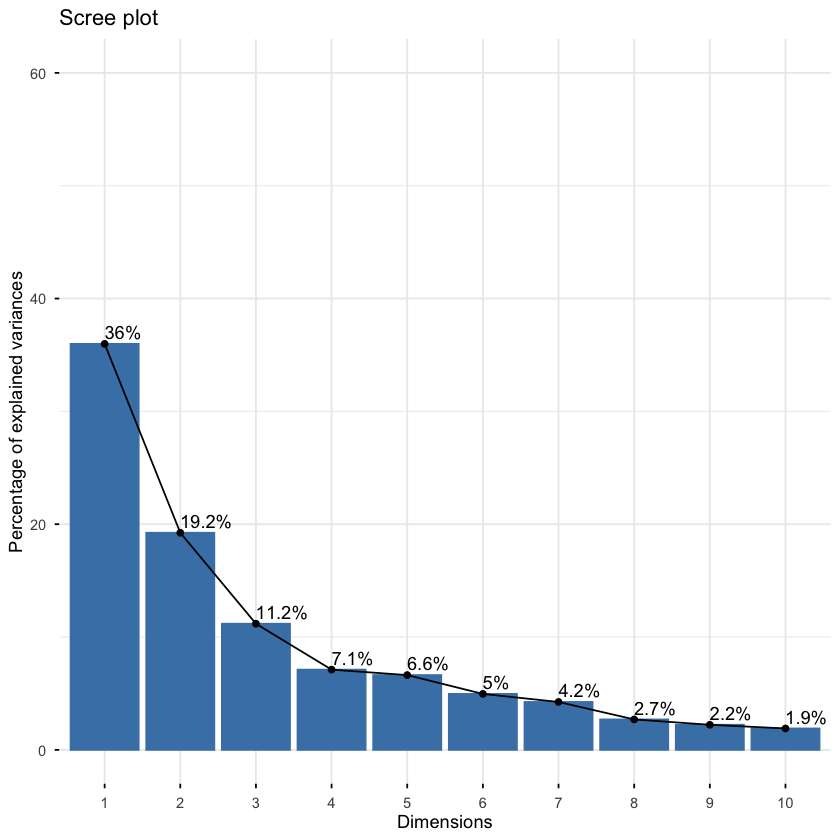

In [11]:
# Scree Plot
fviz_eig(pca, addlabels = TRUE, ylim = c(0, 60))

In [12]:
# Cos²
round(pca$var$cos2, 3)

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
Alcohol,0.089,0.590,0.063,0.000,0.063
Malic acid,0.284,0.123,0.012,0.263,0.003
Ash,0.000,0.249,0.565,0.039,0.022
Alcalinity of ash,0.264,0.000,0.548,0.003,0.004
Magnesium,0.085,0.226,0.027,0.142,0.430
Total phenols,0.733,0.012,0.030,0.038,0.015
Flavanoids,0.843,0.000,0.032,0.022,0.008
Nonflavanoid phenols,0.419,0.002,0.042,0.028,0.224
Proanthocyanins,0.458,0.004,0.033,0.142,0.023
Color intensity,0.041,0.697,0.027,0.005,0.004


In [13]:
# Contribución de las variables (%)
round(pca$var$contrib, 2)

,Dim.1,Dim.2,Dim.3,Dim.4,Dim.5
Alcohol,1.90,23.60,4.36,0.00,7.28
Malic acid,6.07,4.91,0.81,28.42,0.40
Ash,0.00,9.94,38.91,4.22,2.57
Alcalinity of ash,5.63,0.01,37.67,0.33,0.42
Magnesium,1.82,9.02,1.84,15.34,49.89
Total phenols,15.67,0.50,2.09,4.10,1.78
Flavanoids,18.01,0.00,2.23,2.42,0.96
Nonflavanoid phenols,8.95,0.06,2.86,3.07,26.02
Proanthocyanins,9.78,0.17,2.27,15.35,2.63
Color intensity,0.87,27.88,1.85,0.52,0.47


* Que porcentaje de la varianza de cada componente es explicada por esa variable

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggpubr package.
  Please report the issue at <https://github.com/kassambara/ggpubr/issues>.”
Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the factoextra package.
  Please report the issue at <https://github.com/kassambara/factoextra/issues>.”


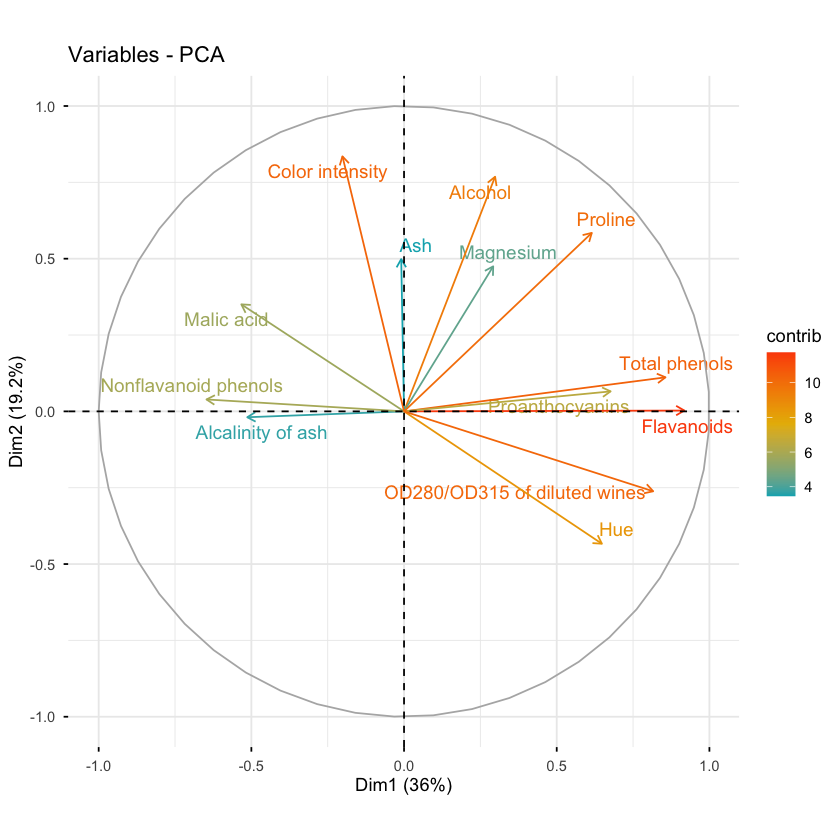

In [14]:
# Círculo de correlación
fviz_pca_var(pca,
             col.var = "contrib",
             gradient.cols = c("#00AFBB", "#E7B800", "#FC4E07"),
             repel = TRUE)

* Círculo de radio 1
* Cuanto mas cerca del 1 estaán las variables, más contribuyen

Ignoring unknown labels:
• linetype : "Clase"


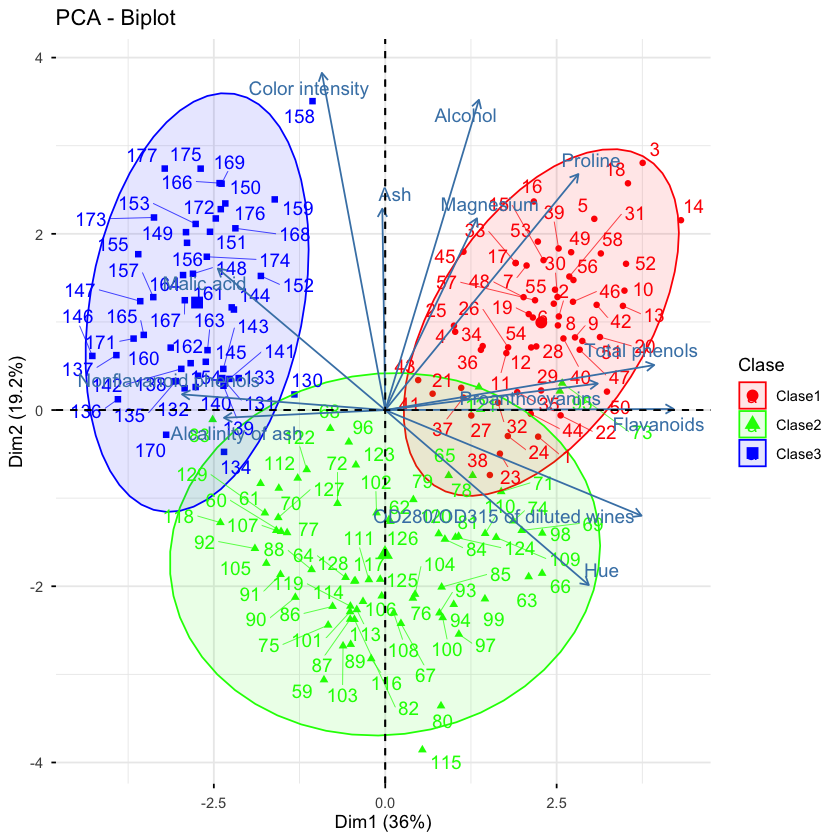

In [15]:
# Biplot (individuos + variables)
fviz_pca_biplot(pca,
                repel = TRUE,
                habillage = clase,
                palette = c("red", "green", "blue"),
                addEllipses = TRUE,
                legend.title = "Clase")

## Iris

In [16]:
# Cargar el dataset
df <- iris
colnames(df) <- c("sepal_length", "sepal_width", "petal_length", "petal_width", "species")
head(df)

,sepal_length,sepal_width,petal_length,petal_width,species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [17]:
# Seleccionar variables numéricas
X <- df %>% select(where(is.numeric))

### PCA

In [18]:
# Aplicar ACP
pca <- PCA(X, graph = FALSE)

Ignoring unknown labels:
• linetype : "Especie"


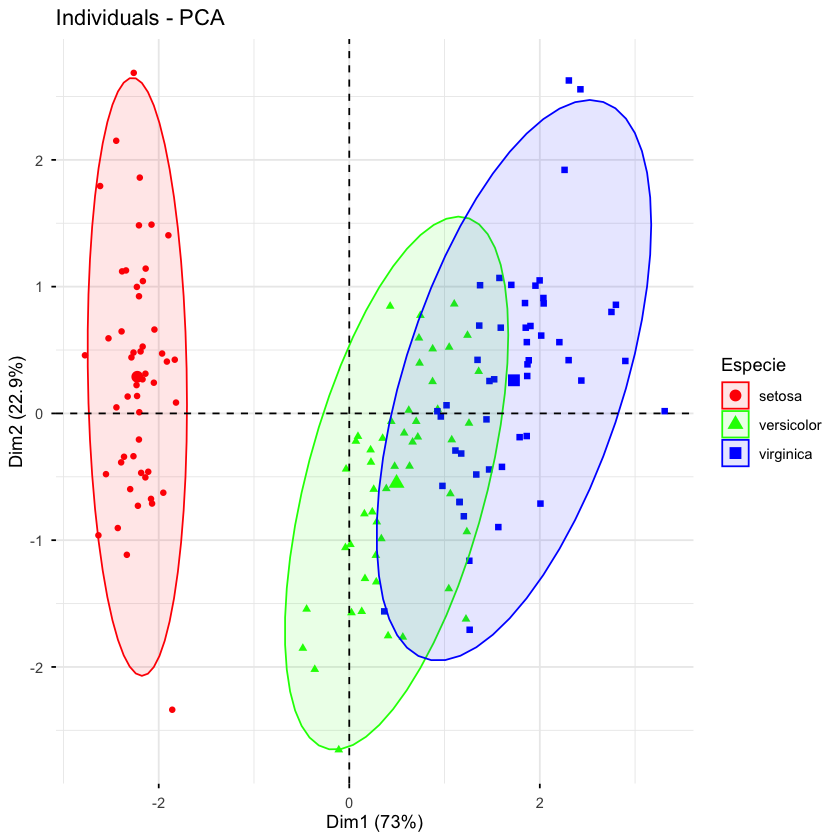

In [19]:
# Visualizar individuos en PC1 y PC2
fviz_pca_ind(pca,
             geom.ind = "point",
             col.ind = df$species,
             palette = c("red", "green", "blue"),
             addEllipses = TRUE,
             legend.title = "Especie")

In [20]:
# Autovalores
pca$eig[,1]

comp 1     comp 2     comp 3     comp 4 
2.91849782 0.91403047 0.14675688 0.02071484

In [21]:
# % de varianza explicada
pca$eig[,2]

comp 1     comp 2     comp 3     comp 4 
72.9624454 22.8507618  3.6689219  0.5178709

In [22]:
# Varianza acumulada
pca$eig[,3]

comp 1    comp 2    comp 3    comp 4 
 72.96245  95.81321  99.48213 100.00000

Warning message in geom_bar(stat = "identity", fill = barfill, color = barcolor, :
“Ignoring empty aesthetic: `width`.”


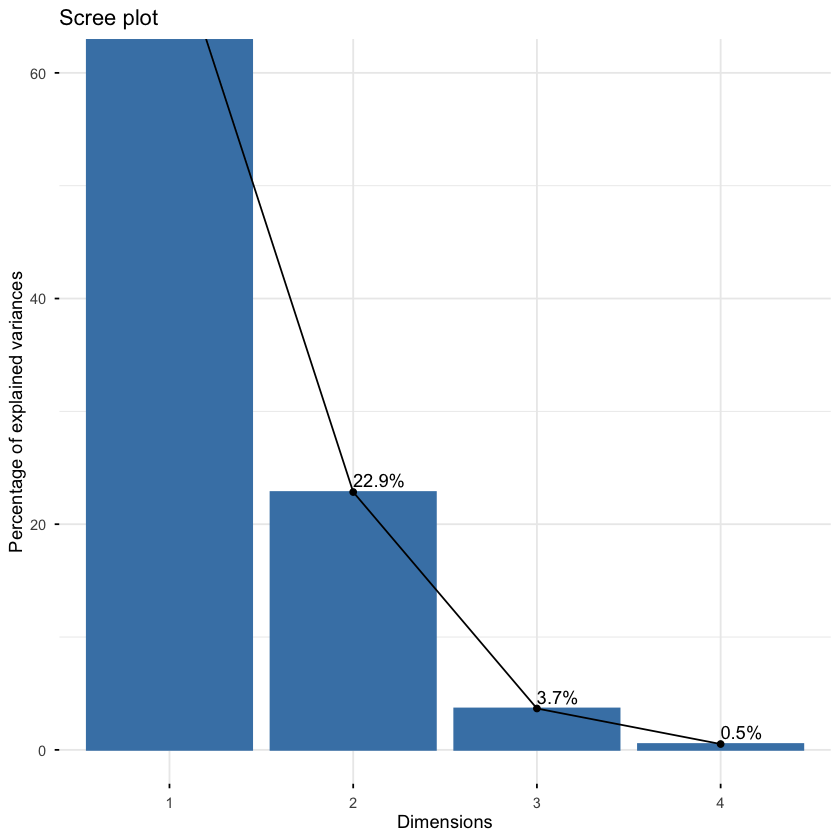

In [23]:
# Scree Plot
fviz_eig(pca, addlabels = TRUE, ylim = c(0, 60))

In [24]:
# Cos²
pca$var$cos2

,Dim.1,Dim.2,Dim.3,Dim.4
sepal_length,0.7924004,0.130198208,0.075987149,0.0014142127
sepal_width,0.2117313,0.779188012,0.008764681,0.0003159971
petal_length,0.9831817,0.000548271,0.002964475,0.0133055723
petal_width,0.9311844,0.004095980,0.059040571,0.0056790544


In [25]:
# Contribución de las variables (%)
pca$var$contrib

,Dim.1,Dim.2,Dim.3,Dim.4
sepal_length,27.150969,14.24440565,51.777574,6.827052
sepal_width,7.254804,85.24748749,5.972245,1.525463
petal_length,33.687936,0.05998389,2.019990,64.232089
petal_width,31.906291,0.44812296,40.230191,27.415396


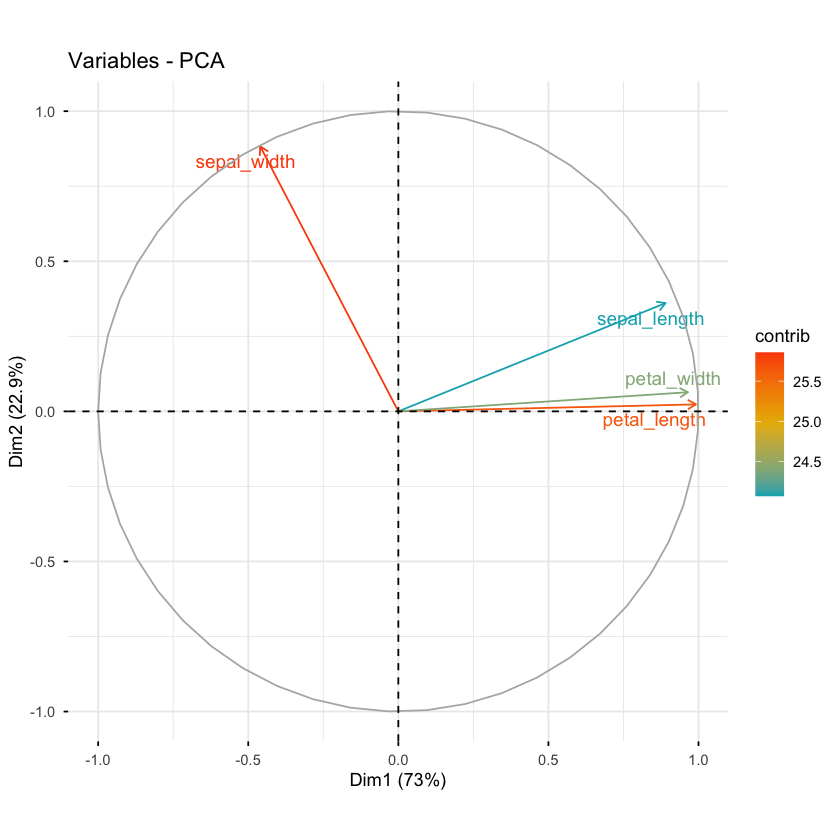

In [26]:
# Círculo de correlación
fviz_pca_var(pca,
             col.var = "contrib",
             gradient.cols = c("#00AFBB", "#E7B800", "#FC4E07"),
             repel = TRUE)

Ignoring unknown labels:
• linetype : "Especie"


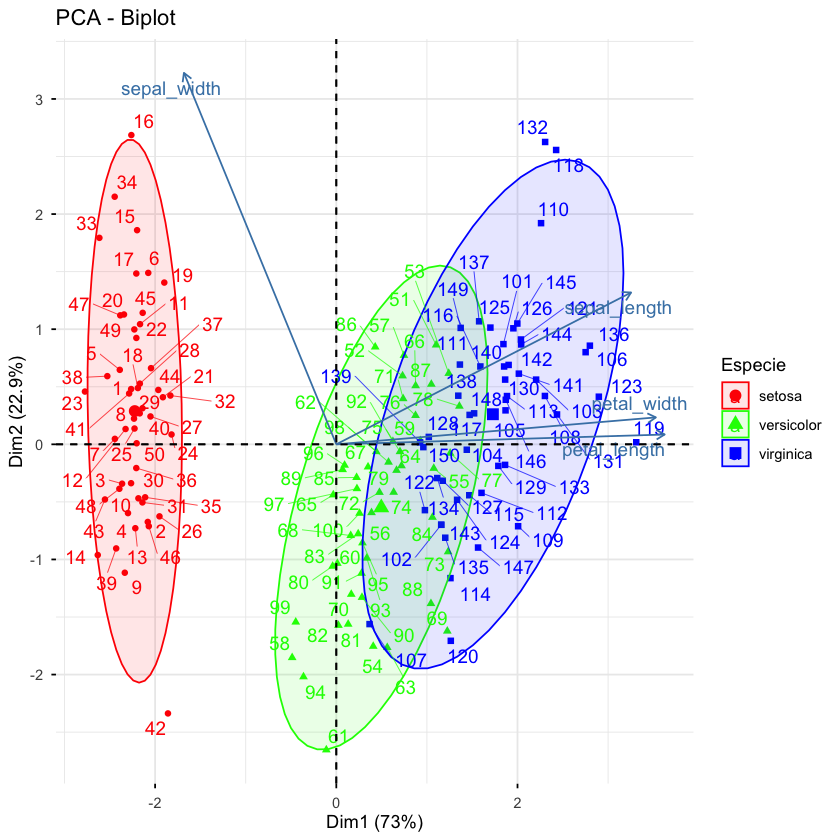

In [27]:
# Biplot (individuos + variables)
fviz_pca_biplot(pca,
                repel = TRUE,
                col.ind = df$species,
                palette = c("red", "green", "blue"),
                addEllipses = TRUE,
                legend.title = "Especie")

### Clustering

In [28]:
# Clustering con K-means sobre componentes principales
set.seed(42)
km <- kmeans(pca$ind$coord[,1:2], centers = 3)

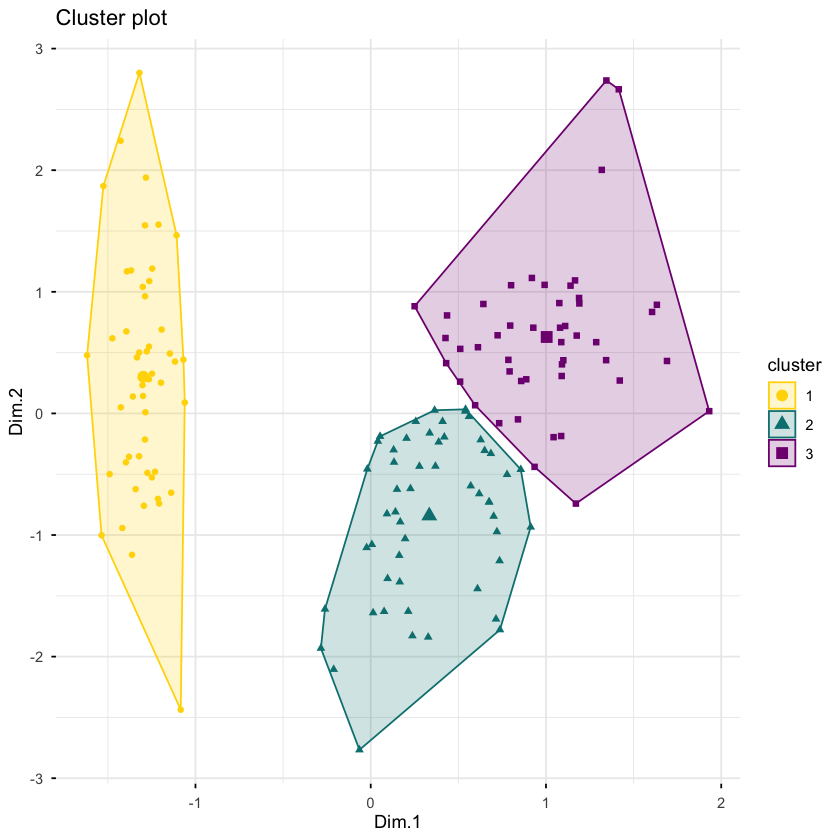

In [29]:
fviz_cluster(km, 
             data = pca$ind$coord[,1:2],
             geom = "point",
             ellipse.type = "convex",
             palette = c("#FFD700", "#008080", "#800080"), # gold, teal, purple en HEX
             ggtheme = theme_minimal())

## Arrestos

In [30]:
# Cargar datos
data("USArrests")
head(data("USArrests"))
df <- na.omit(USArrests)

[1] "USArrests"

In [31]:
# Escalar (normalizar) variables
df_s <- scale(df)

In [32]:
# Calcular distancias (euclidiana por defecto)
d <- dist(df_s, method = "euclidean")

In [33]:
# Clustering jerárquico (complete linkage o Ward)
hc_complete <- hclust(d, method = "complete")
hc_ward     <- hclust(d, method = "ward.D2")

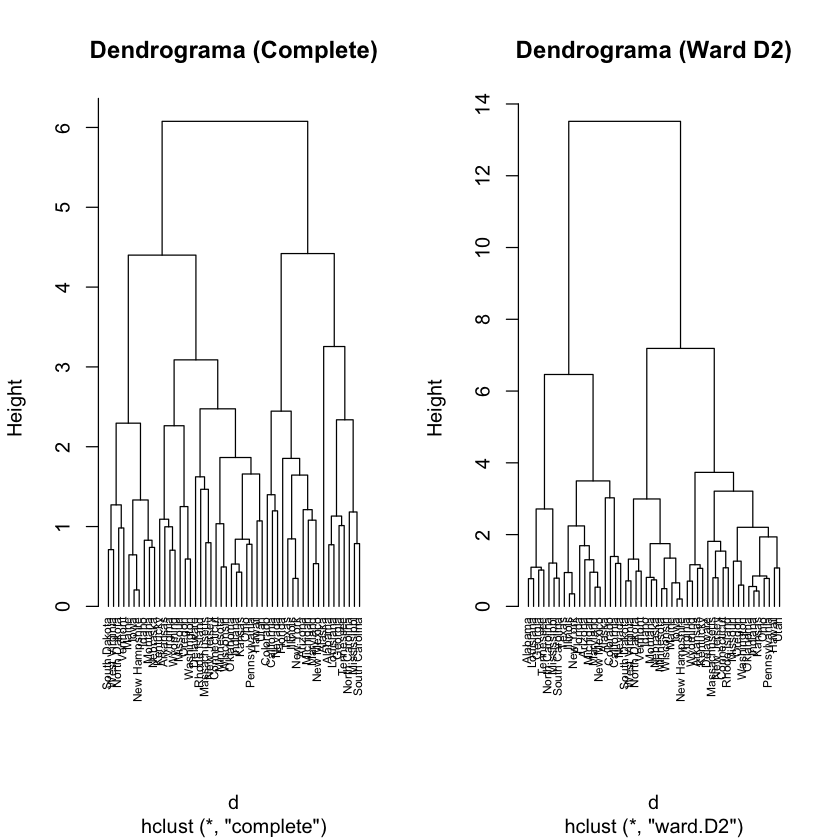

In [34]:
# Graficar dendrogramas
par(mfrow = c(1, 2))
plot(hc_complete, main = "Dendrograma (Complete)", cex = 0.6, hang = -1)
plot(hc_ward,     main = "Dendrograma (Ward D2)",  cex = 0.6, hang = -1)

In [35]:
# Elegir número de clusters y cortar árbol
k <- 4
clusters <- cutree(hc_ward, k = k)

In [36]:
# Ver cuántos elementos en cada clúster
table(clusters)

clusters
 1  2  3  4 
 7 12 19 12 

In [37]:
# Sumarizar características promedio por clúster
aggregate(df, by = list(cluster = clusters), FUN = mean)

cluster,Murder,Assault,UrbanPop,Rape
<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,14.671429,251.2857,54.28571,21.68571
2,10.966667,264.0000,76.50000,33.60833
3,6.210526,142.0526,71.26316,19.18421
4,3.091667,76.0000,52.08333,11.83333
